In [1]:
import pandas as pd

path="data/all_data_M_2023.xlsx"

df = pd.read_excel(path, sheet_name="All May 2023 data")

#Display dataset shape and the firsr few rows
print("Rows and columns", df.shape)
df.head()


Rows and columns (413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [2]:
# Filter occupations related to AI, Data Science, and Software Development

import numpy as np 
import matplotlib.pyplot as plt

# Keep only relevant columns
use_cols = ["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN", "A_PCT10", "A_PCT90", "AREA_TITLE"]
df_filtered = df[use_cols].copy()

# Convert numeric columns safely
df_filtered["TOT_EMP"] = pd.to_numeric(df_filtered["TOT_EMP"], errors="coerce")
df_filtered["A_MEAN"] = pd.to_numeric(df_filtered["A_MEAN"], errors="coerce")
df_filtered["A_PCT10"] = pd.to_numeric(df_filtered["A_PCT10"], errors="coerce")
df_filtered["A_PCT90"] = pd.to_numeric(df_filtered["A_PCT90"], errors="coerce")

# Filter for nationallevel data (United States)
national = df_filtered[df_filtered["AREA_TITLE"].str.contains("United States", case=False, na=False)].copy()
if national.empty:
    national = df_filtered.copy()

#Define keywords to capture AI/Data?Software related occupations
keywords = [
    "data", "software", "developer", "programmer", "database",
    "machine", "research scientist", "statistician",
    "mathematician", "operations research", "computer", "information", "analyst"
]

# Create Lowercase column for pattern matching
national["title_low"] = national["OCC_TITLE"].str.lower()

# Keep rows containing any of those keywords
mask = np.zeros(len(national), dtype=bool)
for kw in keywords:
    mask |= national["title_low"].str.contains(kw, na=False)

subset = national[mask].copy()

print("Number of matching occupations:", subset["OCC_TITLE"].nunique())



Number of matching occupations: 103


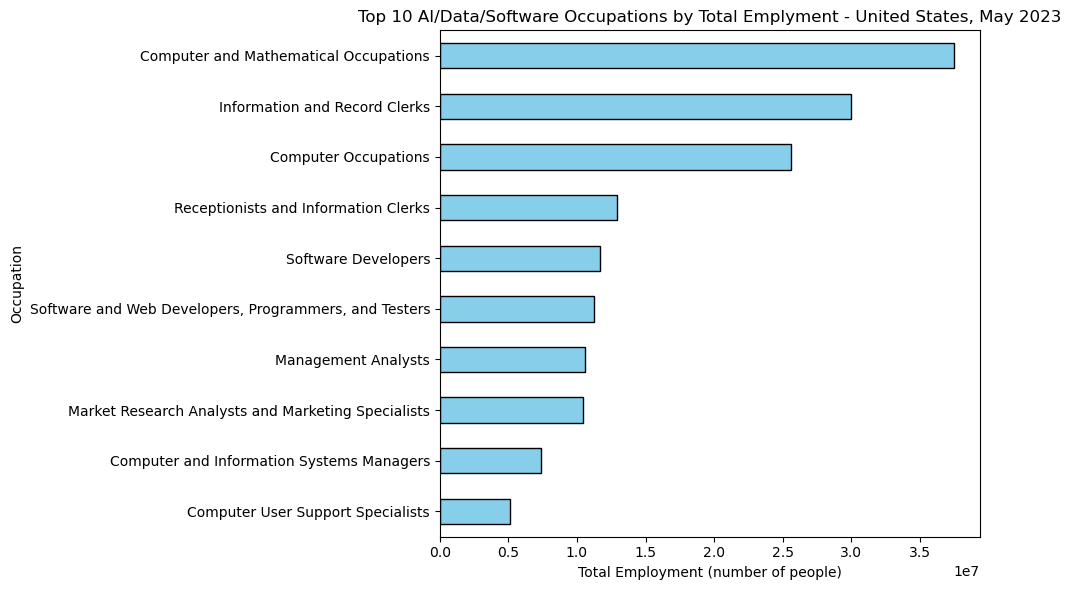

In [3]:
# Group by occupation and calculate total employment
agg = (subset.groupby("OCC_TITLE", dropna=True)["TOT_EMP"]
       .sum(min_count=1)
       .dropna()
       .sort_values(ascending=False))

# Select top 10 occupations
top10 = agg.head(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
top10.plot(kind="barh", color="skyblue", edgecolor="black")

plt.xlabel("Total Employment (number of people)")
plt.ylabel("Occupation")
plt.title("Top 10 AI/Data/Software Occupations by Total Emplyment - United States, May 2023")

plt.tight_layout()

plt.savefig(r"C:\Users\Clara\Documents\NetBeansProjects\bsc-4th-data-visualisation-2022475\figures\V1_total_employment.png", dpi=200, bbox_inches="tight")

plt.show()

 Visualization 1 — Total Employment by Occupation (Bar Chart) 

**Objective:**  
To identify the most employed occupations in the AI, Data Science, and Software Development fields as of May 2023. This visualization provides a clear overview of which roles dominate the job market by number of people employed.

**Why this chart type:**  
This horizontal bar chart is ideal for comparing discrete categories such as job titles. It allows easy reading of long occupation names while maintaining a clear sense of scale. The sorted bars emphasize the relative size of each occupation in terms of employment.

**What I learned:**  
The most employed roles are general categories like “Computer and Mathematical Occupations” and “Information Clerks,” rather than niche AI or Data Science titles. This suggests that the AI workforce is still embedded in broader tech-related occupations, where generalist positions dominate employment numbers.

C:\Users\Clara\AppData\Local\Temp\ipykernel_8596\67399587.py:20: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




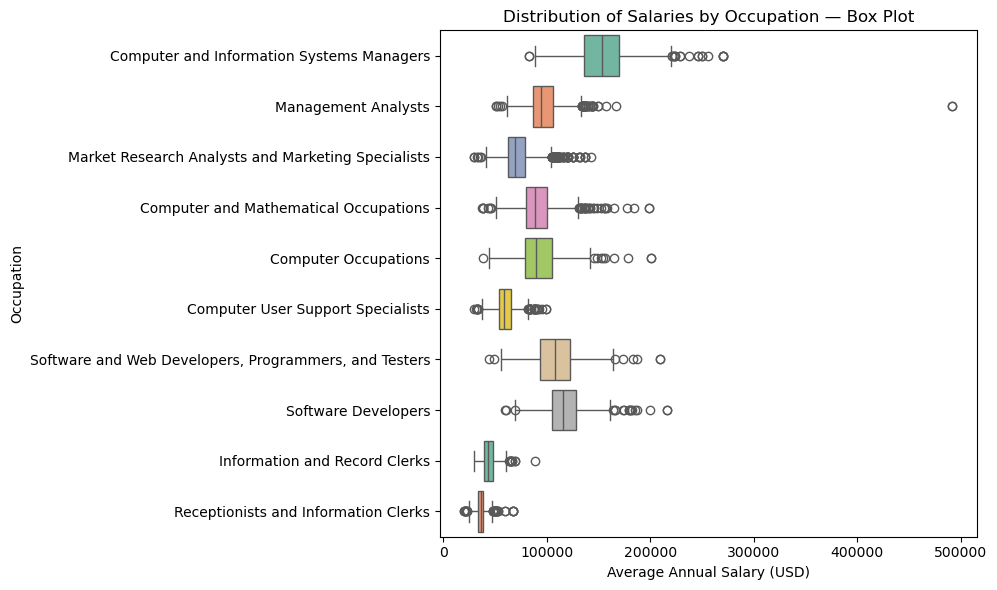

In [9]:
# Group by occupation and calculate the mean of A_MEAN

import seaborn as sns

# Get the top 10 occupations by total employment (from V1)
top10_titles = (
    subset.groupby("OCC_TITLE")["TOT_EMP"]
    .sum().sort_values(ascending=False)
    .head(10).index.tolist()
)

# Filter subset to include only those top 10
subset_top10 = subset[subset["OCC_TITLE"].isin(top10_titles)].copy()

# Drop rows with missing salary data
box_data = subset_top10.dropna(subset=["A_MEAN", "OCC_TITLE"])

# Plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=box_data, x="A_MEAN", y="OCC_TITLE", orient="h", palette="Set2")

plt.xlabel("Average Annual Salary (USD)")
plt.ylabel("Occupation")
plt.title("Distribution of Salaries by Occupation — Box Plot")

plt.tight_layout()

plt.savefig(r"C:\Users\Clara\Documents\NetBeansProjects\bsc-4th-data-visualisation-2022475\figures\V2_total_employment.png", dpi=200, bbox_inches="tight")

plt.show()


Visualization 2 — Salary Distribution by Occupation (Box Plot)

**Objective:**  
To analyze and compare the variation in average annual salaries across the top 10 most employed occupations in the AI/Data/Software field. This visualization helps identify which roles have higher or more variable pay.

**Why this chart type:**  
Rather than focusing on averages alone, a box plot provides a deeper view into salary distribution within each occupation. It highlights the overall range of salaries, shows where most values cluster, and draws attention to roles with unusually high or low earnings. This makes it easier to spot inconsistencies or anomalies that a standard bar chart might hide.

**What I learned:**  
There’s a noticeable gap in salary variability across occupations. Some roles like “Information Clerks” have tightly clustered wages, while others like “Managers” or “Computer Systems Managers” show wide ranges and outliers. This highlights the uneven salary structure across AI-related job titles.

**Note:**  
Only occupations with available salary data were included. This visualization was created using Seaborn to enhance visual clarity.

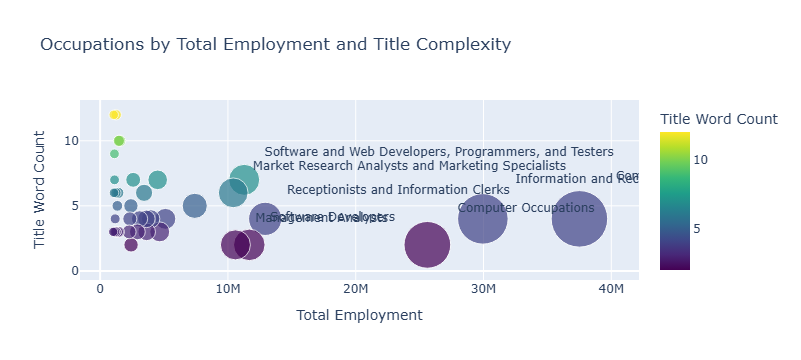

In [5]:

import plotly.express as px


subset["title_word_count"] = subset["OCC_TITLE"].str.split().str.len()


grouped = (
    subset.groupby("OCC_TITLE")
    .agg({
        "TOT_EMP": "sum",
        "title_word_count": "mean"
    })
    .dropna()
    .sort_values("TOT_EMP", ascending=False)
    .reset_index()
)

top40 = grouped.head(40).copy()

top40["show_label"] = top40.apply(
    lambda row: row["OCC_TITLE"] if row["TOT_EMP"] > 10_000_000 else "",
    axis=1
)


fig = px.scatter(
    top40,
    x="TOT_EMP",
    y="title_word_count",
    text="show_label",
    #text="OCC_TITLE",
    size="TOT_EMP",
    color="title_word_count",
    labels={
        "TOT_EMP": "Total Employment",
        "title_word_count": "Title Word Count"
    },
    title="Occupations by Total Employment and Title Complexity",
    hover_name="OCC_TITLE",
    size_max=40,
    color_continuous_scale="Viridis"
)

fig.update_traces(textposition="top right")
fig.update_layout(height=600)
#fig.savefig(r"C:\Users\Clara\Documents\NetBeansProjects\bsc-4th-data-visualisation-2022475\figures\V2_total_employment.png", dpi=200, bbox_inches="tight")

fig.show()


Visualization 3 — Employment vs. Title Complexity (Interactive Scatter Plot)

**Objective:**  
To explore the relationship between occupation size (measured by total employment) and job title complexity (approximated by the number of words in the title). The aim is to uncover whether broader or more generic job titles tend to dominate the workforce in AI/Data/Software roles.

**Why this chart type:**  
A scatter plot is a strong choice for examining patterns or trends between two numerical dimensions. By adding interactivity through Plotly, this visualization allows deeper inspection without overcrowding the display. It also uses point size and color to encode additional information, making the comparison more intuitive and engaging.

**What I learned:**  
The chart shows that roles with shorter and simpler titles tend to employ more people, while complex job titles appear in lower-employment positions. This implies that broad titles are used for mass hiring, while specialized roles remain smaller in scale.

**Note:**  
This chart intentionally avoids salary data to explore structural aspects of job titles. Labels were selectively shown to reduce clutter while still highlighting key roles. Plotly was used to enhance readability and allow interactive data exploration.

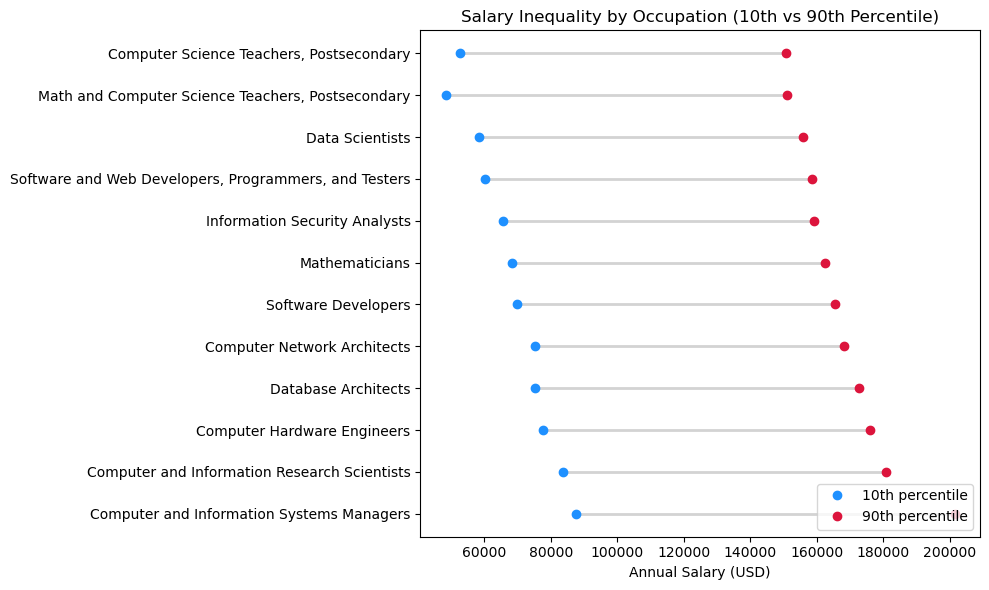

In [8]:


import matplotlib.pyplot as plt

salary_range = subset.dropna(subset=["A_PCT10", "A_PCT90"])

salary_stats = (
    salary_range.groupby("OCC_TITLE")[["A_PCT10", "A_PCT90"]]
    .mean()
    .dropna()
    .sort_values("A_PCT90", ascending=False)
    .head(12)  # top 12 ocupaciones con mayor percentil 90
    .reset_index()
)

plt.figure(figsize=(10, 6))

for i in range(len(salary_stats)):
    plt.plot(
        [salary_stats["A_PCT10"][i], salary_stats["A_PCT90"][i]],
        [i, i],
        color="lightgray",
        linewidth=2
    )
    plt.plot(salary_stats["A_PCT10"][i], i, "o", color="dodgerblue", label="10th percentile" if i == 0 else "")
    plt.plot(salary_stats["A_PCT90"][i], i, "o", color="crimson", label="90th percentile" if i == 0 else "")

plt.yticks(range(len(salary_stats)), salary_stats["OCC_TITLE"])
plt.xlabel("Annual Salary (USD)")
plt.title("Salary Inequality by Occupation (10th vs 90th Percentile)")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(r"C:\Users\Clara\Documents\NetBeansProjects\bsc-4th-data-visualisation-2022475\figures\V4_salary_inequality_dumbbell.png", dpi=200, bbox_inches="tight")
plt.show()


Visualization 4 — Dumbbell Plot: Salary Inequality by Occupation

**Objective:**  
To visualize the income disparity within AI, Data, and Software-related occupations. The goal is to compare the 10th and 90th percentile salaries for each role, highlighting how wide the salary range is within the same job title.

**Why this chart type:**  
The dumbbell plot allows to visualize both low and high-end salaries side by side for each role, clearly exposing the span between the 10th and 90th percentiles. Instead of compressing this variation into a single value, it reveals the salary spectrum within each occupation.

**What I learned:** 
Some occupations, like Computer and Information Systems Managers or Research Scientists, have much wider salary ranges than others, suggesting greater variability due to seniority levels, specialization, or geographic location. Meanwhile, roles like teachers or analysts show much tighter ranges, reflecting more standardized compensation structures. This highlights that job titles alone don’t tell the full story — understanding internal variability is essential to grasp the real value and career progression potential within these fields.

**Harvard Referencing**

- McKinney, W. (2017) Python for Data Analysis: Data Wrangling with Pandas, NumPy, and IPython. 2nd edn. Sebastopol, CA: O’Reilly Media.

- Ahmed, T. (2025) CA1-type Data Visualisation Tutorial Conducted in Class: Code developed interactively. Lecture notes, BSc in Computing – Year 4, CCT College Dublin.
- Ahmed, T. (2025) Interactive Visualisation using Plotly. Lecture notes, BSc in Computing – Year 4, CCT College Dublin.

- U.S. Bureau of Labor Statistics (2024) Occupational Employment and Wage Statistics – May 2022 and May 2023. Available at: https://www.bls.gov/oes/tables.htm
 (Accessed: 25 October 2025).

- Waskom, M. L., (2021). seaborn: statistical data visualization. Journal of Open Source Software, 6(60), 3021, https://doi.org/10.21105/joss.03021.

-  J. D. Hunter, "Matplotlib: A 2D Graphics Environment", Computing in Science & Engineering, vol. 9, no. 3, pp. 90-95, 2007.

-  Plotly Technologies Inc. (2015) Collaborative data science. Available at: https://plotly.com/python/
  